# LGL-VAE: manuální workflow

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(r'D:/VS/LGL-VAE')
sys.path.insert(0, str(PROJECT_ROOT))

from manual_run import (
    step_1_load_existing_model_and_plot,
    step_2_inspect_fasta, step_3_preview_sequences,
    step_4_encode_one_sequence, step_5_build_model,
    step_6_make_dataset, step_7_train_full_model,
    step_8_train_dca_model, step_10_plot_latent_space,
    step_11_plot_decoder_grid,step_9_generate_hamiltonian_map,
     step_12_plot_dca_model,step_13_plot_dca_3d,
     step_14_plot_dca_sequences, step_15_evaluate_dca_reconstruction, run_steps,
)

FASTA_PATH = str(PROJECT_ROOT / 'result' / 'model_globin' / 'globin_pfam_training_set.fasta')
MODEL_PATH = str(PROJECT_ROOT / 'result' / 'model_globin' / 'model_5')
DCA_MODEL_PATH = str(Path(MODEL_PATH).parent / 'trained_dca_manual.pkl_1')
DCA_PICKLE_PATH = str(Path(MODEL_PATH) / 'latent_generative_landscape.pkl')
print('Projekt:', PROJECT_ROOT)
print('FASTA:', FASTA_PATH)
print('Natrénované DCA:', DCA_MODEL_PATH)


Projekt: D:\VS\LGL-VAE
FASTA: D:\VS\LGL-VAE\result\model_globin\globin_pfam_training_set.fasta
Natrénované DCA: D:\VS\LGL-VAE\result\model_globin\trained_dca_manual.pkl_1


## 1. Načtení existujícího modelu (funkce 1)

Nejdřív načti a zobraz už natrénovaný VAE z `MODEL_PATH`.



Krok 1: načtení už natrénovaného modelu a vizualizace


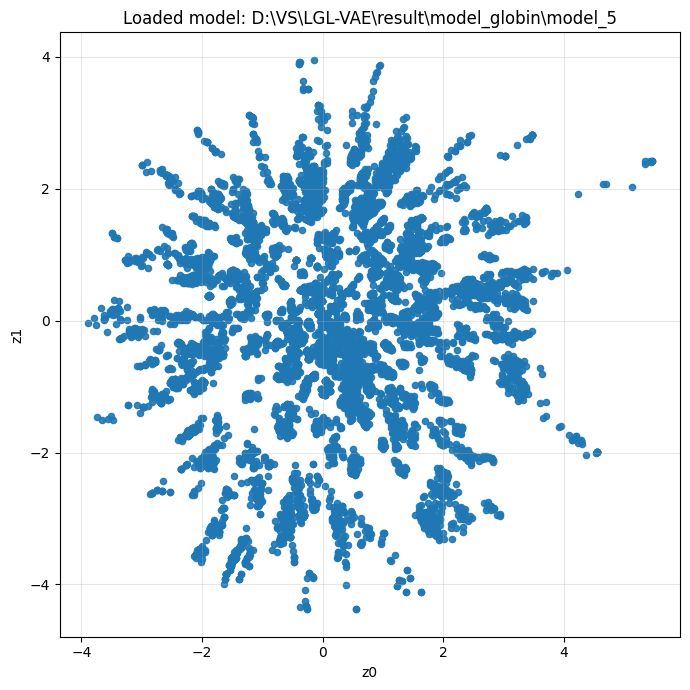

Načtený model byl vizualizován a uložen do: D:\VS\LGL-VAE\result\model_globin\model_5\loaded_model.png


In [2]:
trained_model = step_1_load_existing_model_and_plot(
    MODEL_PATH, FASTA_PATH, output_path=str(Path(MODEL_PATH) / 'loaded_model.png')
)


## 2. Kontrola dat a sestavení modelu (funkce 2-5)

Zkontroluj FASTA, zobraz sekvence, zakoduj jednu sekvenci a sestav architekturu VAE.


In [ ]:
run_steps([2, 3, 4, 5], fasta_path=FASTA_PATH)


## 3. Dataset (funkce 6, volitelná)

Vytvoř TensorFlow dataset a prohlédni si jeden batch. Tento pomocný krok není nutný před trénováním.


In [ ]:
dataset = step_6_make_dataset(FASTA_PATH, batch_size=16)


## 4. Trénování VAE (funkce 7)

Natrénuje model a uloží ho do `MODEL_PATH`. 


In [ ]:
EPOCHS = 1000
BATCH_SIZE = 16
trained_model = step_7_train_full_model(
    FASTA_PATH,
    model_out=MODEL_PATH,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
)


## 5. Trénování DCA (funkce 8)

Natrénuje DCA model z FASTA alignmentu a uloží ho do `DCA_MODEL_PATH`.


In [9]:
trained_dca = step_8_train_dca_model(
    FASTA_PATH,
    model_out=DCA_MODEL_PATH,
)



Krok 8: trénink DCA modelu
Natrénovaný DCA model uložen do: D:\VS\LGL-VAE\result\model_globin\trained_dca_manual.pkl_1


## 6. Hamiltonova mapa (funkce 9)

Po natrénovaní VAE i DCA vytvoř Hamiltonovu mapu a ulož ji do `DCA_PICKLE_PATH`.


In [10]:
step_9_generate_hamiltonian_map(
    MODEL_PATH, FASTA_PATH, output_path=DCA_PICKLE_PATH, resolution=500,
    dca_model_path=DCA_MODEL_PATH,
)



Krok 9: generování originální Hamiltonian mapy
Originální Hamiltonian mapa uložena do: D:\VS\LGL-VAE\result\model_globin\model_5\latent_generative_landscape.pkl


'D:\\VS\\LGL-VAE\\result\\model_globin\\model_5\\latent_generative_landscape.pkl'

## 7. Další vizualizace VAE (funkce 10 a 11)

Tyto grafy načítají již natrénovaný model a zobrazují jeho latentní prostor a mapu decoderu.


Krok 10: zobrazení latentního prostoru


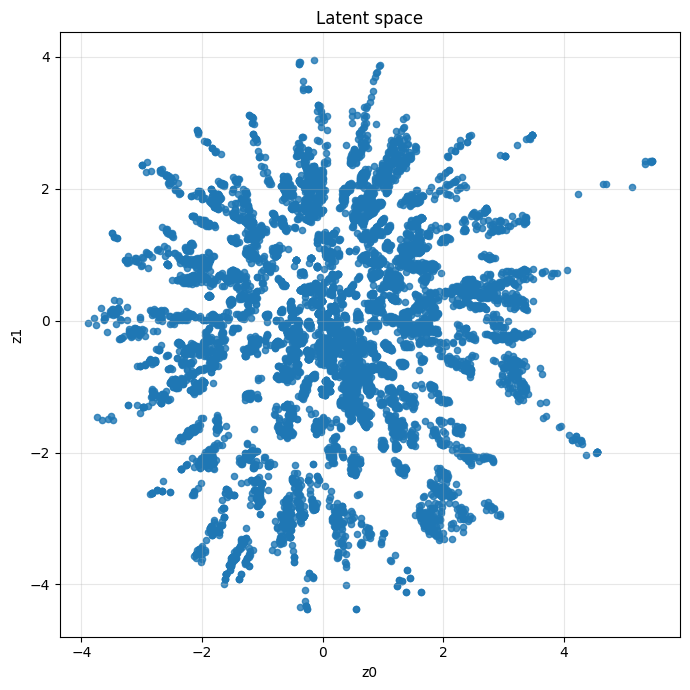

Obrázek uložen do: D:\VS\LGL-VAE\result\model_globin\model_5\latent_space.png


In [3]:
step_10_plot_latent_space(
    MODEL_PATH, FASTA_PATH, output_path=str(Path(MODEL_PATH) / 'latent_space.png')
)



Krok 11: mapa decoderu v latentním prostoru


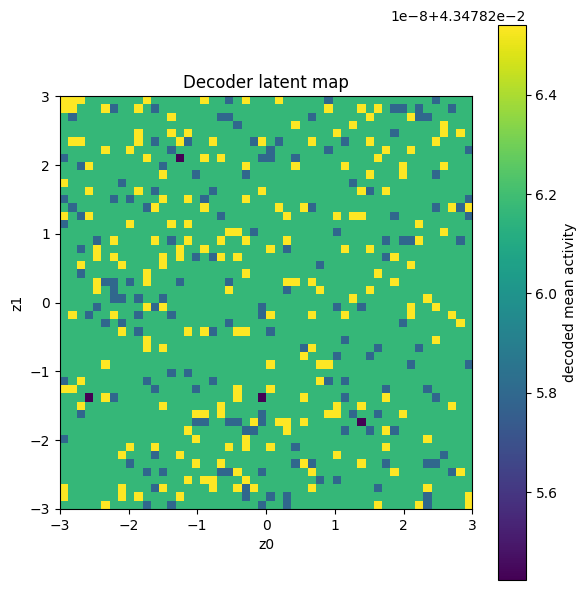

Obrázek uložen do: D:\VS\LGL-VAE\result\model_globin\model_5\decoder_map.png


In [4]:
step_11_plot_decoder_grid(
    MODEL_PATH, output_path=str(Path(MODEL_PATH) / 'decoder_map.png'), grid_size=50
)

## 8. Zobrazení DCA mapy a sekvencí (funkce 12-14)

Krok 12 zobrazí 2D Hamiltonovu mapu, krok 13 nabídne interaktivní 3D pohled a krok 14 zobrazí trénovací sekvence v latentním prostoru. V kroku 14 lze volitelně nastavit `sequence` a `similarity_threshold` pro zvýraznění podobných sekvencí.



Krok 12: zobrazení DCA Hamiltonovy mapy


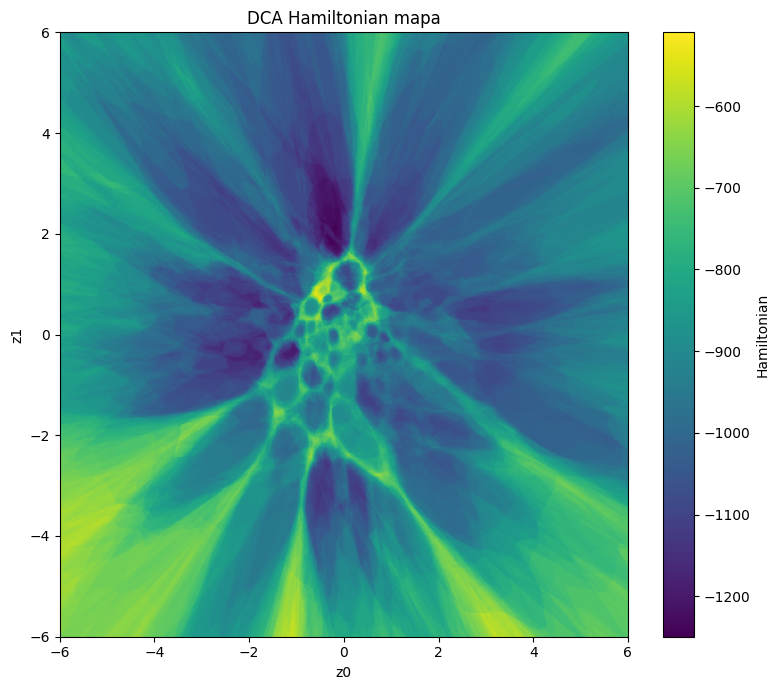

DCA Hamiltonova mapa uložena do: D:\VS\LGL-VAE\result\model_globin\model_5\dca_map.png


In [6]:
step_12_plot_dca_model(
    DCA_PICKLE_PATH, output_path=str(Path(MODEL_PATH) / 'dca_map.png')
)


In [5]:
step_13_plot_dca_3d(
    DCA_PICKLE_PATH, output_path=str(Path(MODEL_PATH) / 'dca_3d.html')
)



Krok 13: interaktivní 3D DCA mapa
Interaktivní 3D mapa uložena do: D:\VS\LGL-VAE\result\model_globin\model_5\dca_3d.html


In [5]:
step_14_plot_dca_sequences(
    DCA_PICKLE_PATH,
    trained_model,
    sequence="tr|A0A3B3HH63|A0A3B3HH63_ORYLA Si:ch211-5k11.8 OS=Oryzias latipes OX=8090 PE=3 SV=1",
    similarity_threshold=40,
    three_dimensional=False,
    output_path=str(Path(MODEL_PATH) / 'dca_landscape_with_sequences.html'),

)



Krok 14: interaktivní DCA mapa sekvencí
Interaktivní 2D mapa sekvencí uložena do: D:\VS\LGL-VAE\result\model_globin\model_5\dca_landscape_with_sequences.html
Vybraná sekvence: tr|A0A3B3HH63|A0A3B3HH63_ORYLA Si:ch211-5k11.8 OS=Oryzias latipes OX=8090 PE=3 SV=1; podobných sekvencí nad hranicí: 843


## 15. Rekonstrukce sekvencí a korelace s DCA

Dekóduje primární latentní vektory trénovacích sekvencí, vyhodnotí shodu a nejistotu dekodéru a porovná DCA Hamiltonian před a po rekonstrukci. Výsledky uloží do CSV a interaktivního korelačního grafu.


In [3]:
step_15_evaluate_dca_reconstruction(
    DCA_PICKLE_PATH,
    trained_model,
    csv_output_path=str(Path(MODEL_PATH) / 'dca_reconstruction_report.csv'),
    plot_output_path=str(Path(MODEL_PATH) / 'dca_reconstruction_correlation.html'),
)



Krok 15: kvalita rekonstrukce sekvencí a korelace s DCA
Vyhodnoceno sekvencí: 10570
Shoda rekonstrukcí: průměr 76.63 %, medián 80.51 %
Změněné pozice: průměr 23.37 %, medián 19.49 %
Nejistota decoderu (normalizovaná entropie): průměr 24.03 %, medián 20.67 %; průměrná jistota 75.48 %
Nejvíce změněná sekvence: tr|A0A0M1J4K8|A0A0M1J4K8_9GAMM GLOBIN domain-containing protein OS=Achromatium sp. WMS3 OX=1604836 GN=TI05_18490 PE=4 SV=1; shoda 17.80 %, změněno 82.20 %
Nejvyšší shoda: tr|A0A2K6G8J5|A0A2K6G8J5_PROCO Neuroglobin OS=Propithecus coquereli OX=379532 GN=NGB PE=3 SV=1; 100.00 %
Nejistější rekonstrukce: tr|A0A448Z0C1|A0A448Z0C1_9STRA GLOBIN domain-containing protein OS=Pseudo-nitzschia multistriata OX=183589 GN=PSNMU_V1.4_AUG-EV-PASAV3_0022630 PE=3 SV=1; entropie 68.31 %, průměrná jistota 31.98 %
Korelace shody s DCA Hamiltonianem (původní sekvence): Pearson r=-0.427, p=0; Spearman r=-0.254, p=7.99e-155
Korelace shody s DCA Hamiltonianem (rekonstruovaná sekvence): Pearson r=-0.321, p=